### Non-Seasonal ARIMA Model

- ARMA(p,q)
- ARIMA(p,d,q)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# ARMA was removed in statsmodels 0.13 -- use ARIMA(order=(p, 0, q)) for an ARMA(p, q) model
from statsmodels.tsa.arima.model import ARIMA

from datetime import datetime
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv('./Time-Series-Analysis-Resources/6-Smooting_Techniques/data/us_airline_carrier_passenger.csv')
df.head()

,month,passengers
0,2000-01-01,46492
1,2000-02-01,48526
2,2000-03-01,58764
3,2000-04-01,56033
4,2000-05-01,58201


- Train data: 2000-01-01 to 2016-12-01   
- Test data: 2017-01-01 to 2019-12-01


In [3]:
df.dtypes

month           str
passengers    int64
dtype: object

In [4]:
df['month'] = pd.to_datetime(df['month'])

In [5]:
# split the data into train and test
cut_off = datetime.strptime('2016-12-01', '%Y-%m-%d')
train_df = df[df['month'] <= cut_off]
test_df = df[df['month'] > cut_off]

In [6]:
# set the time as index
train_df.set_index('month', inplace=True)
test_df.set_index('month', inplace=True)

In [7]:
train_df.head()

,passengers
month,
2000-01-01,46492
2000-02-01,48526
2000-03-01,58764
2000-04-01,56033
2000-05-01,58201


In [8]:
train_df.tail()

,passengers
month,
2016-08-01,73450
2016-09-01,66477
2016-10-01,69539
2016-11-01,66591
2016-12-01,67983


In [9]:
test_df.head()

,passengers
month,
2017-01-01,62621
2017-02-01,58377
2017-03-01,72962
2017-04-01,70262
2017-05-01,73679


In [10]:
test_df.tail()

,passengers
month,
2019-08-01,83784
2019-09-01,72590
2019-10-01,78617
2019-11-01,73074
2019-12-01,79302


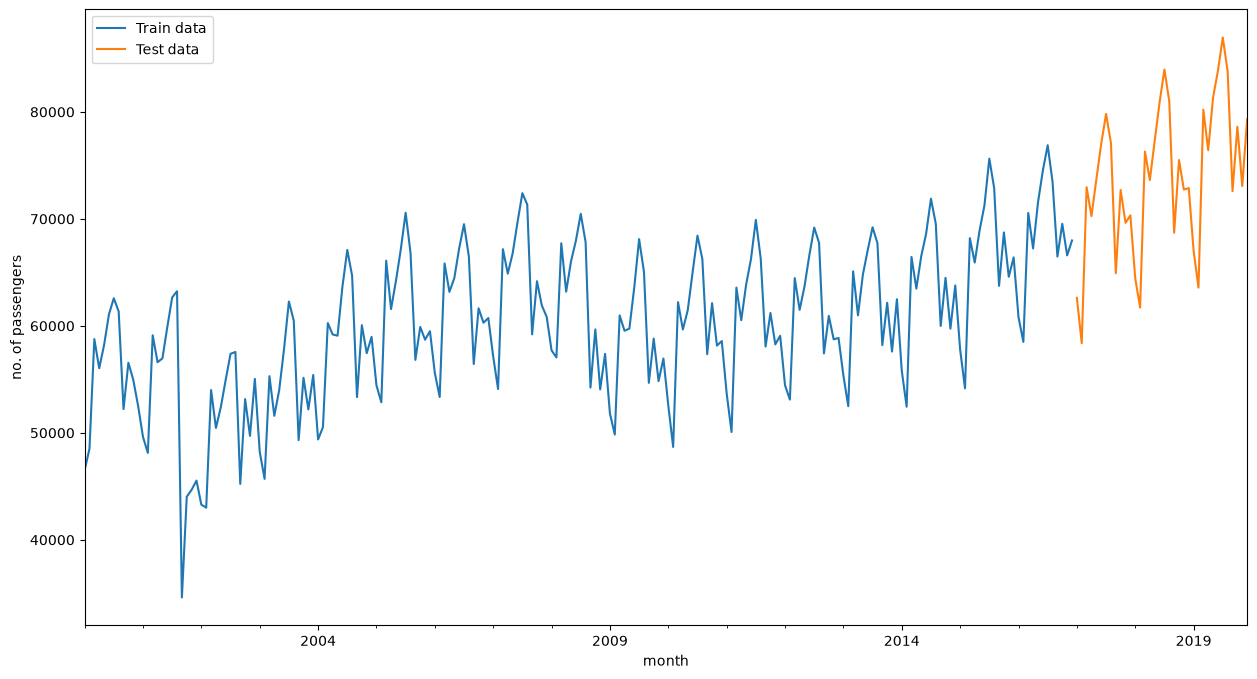

In [11]:
# visualize
fig,ax = plt.subplots(figsize=(15,8))
train_df.plot(kind='line',ax=ax, label='Train')
test_df.plot(kind='line',ax=ax, label='Test')
plt.xlabel('month')
plt.ylabel('no. of passengers')
plt.legend(['Train data','Test data'])
plt.show()


# ARMA (p,q)

## Steps for ARMA

1. Augmented Dickey-Fuller unit root test for Stationary.

2. If not stationary convert into Stationary.

3. Find p, q
   - **p:** AR order (PACF)
   - **q:** MA order (ACF)

4. Train ARMA model.
5. Convert the stationary to non-stationary.


### Step-1: Augmented Dickey-Fuller

- significance level = 5%
  - p-value = 0.025

- **$Ho$:** Data is non-stationary (p-value >= 0.025) : bulk region

- **$Hₐ$:** Data is stationary (p-value < 0.025) : critical region


In [12]:
from statsmodels.tsa.stattools import adfuller

In [13]:
adfuller(train_df)

(-0.9529124941948443,
 0.7700488660390641,
 13,
 190,
 {'1%': np.float64(-3.4652439354133255),
  '5%': np.float64(-2.8768752281673717),
  '10%': np.float64(-2.574944653739612)},
 np.float64(3449.617955746232))

- From the above test, p-value is greater than 0.025, hence with 5% significance, data is non-stationary  
- So, I need to difference to convert data into stationary 

### Step-2: Convert non-stattationary to stationary

In [14]:
stationary_train_df = train_df.diff() # difference
stationary_train_df.dropna(inplace=True) # drop null values

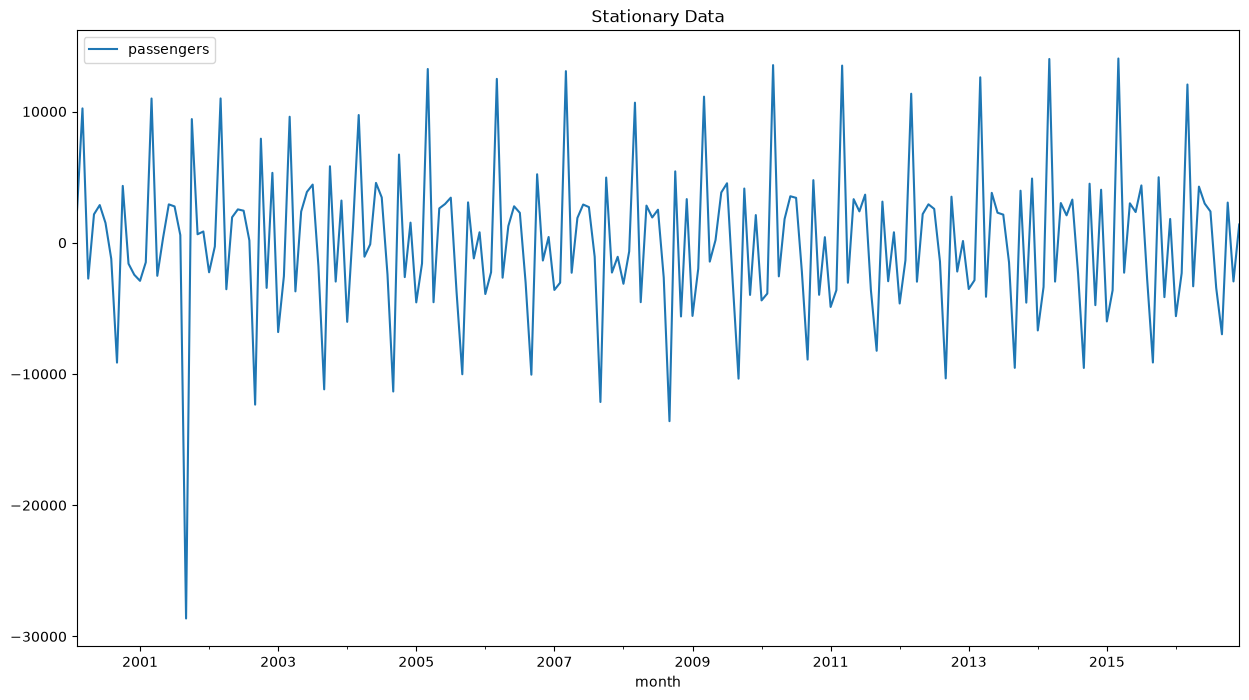

In [15]:
fig,ax = plt.subplots(figsize=(15,8))
stationary_train_df.plot(kind='line',ax=ax)
plt.title('Stationary Data')
plt.show()

In [16]:
# test for stationary
adfuller(stationary_train_df)

(-3.770003898122386,
 0.0032295638943138946,
 12,
 190,
 {'1%': np.float64(-3.4652439354133255),
  '5%': np.float64(-2.8768752281673717),
  '10%': np.float64(-2.574944653739612)},
 np.float64(3430.8048684881874))

- From the above results, p-value is 0.003 which is less than 0.025, hence, p-value falls in critical region, therefore we are rejecting the null hypothesis and accepting the alternate hypothesis which is data is stationary 

### Step-3:   
Find p,q.  

p: AR order(pacf).  
q: MA order(acf)

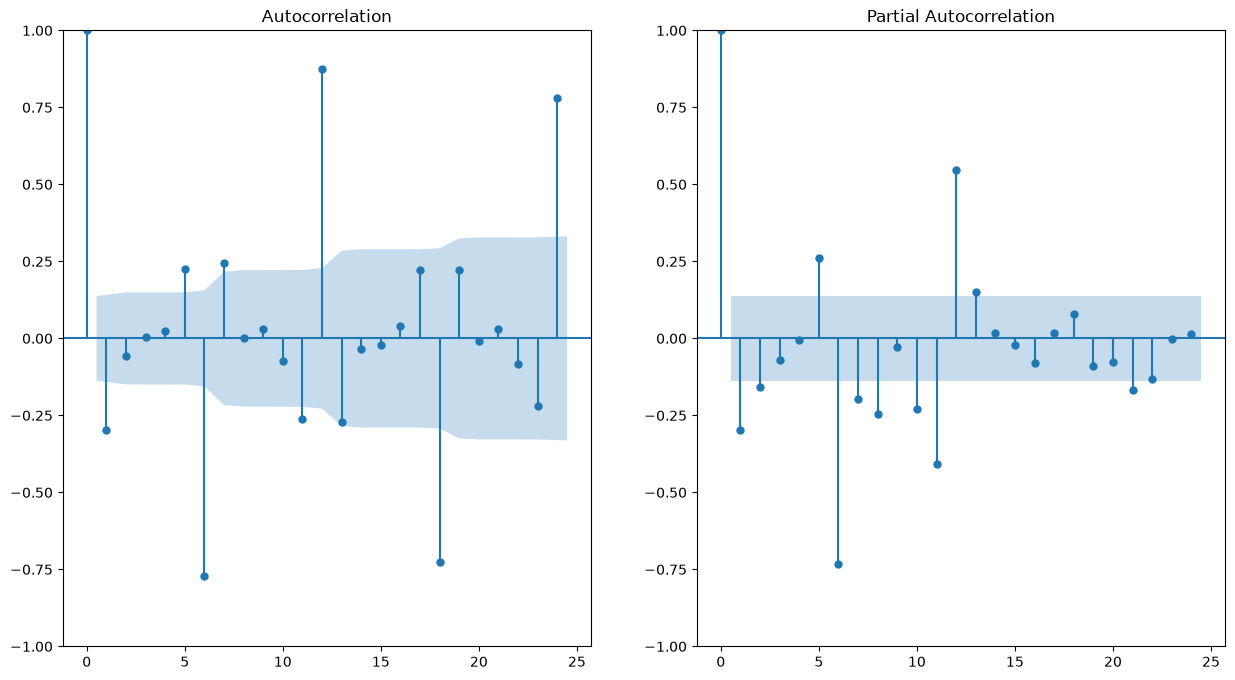

In [17]:
fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(15,8))
fig = plot_acf(stationary_train_df,ax=ax[0])
fig = plot_pacf(stationary_train_df,ax=ax[1])

p=6, q=6

### Step-4: Train ARMA model

In [18]:
p,q=(6,6)
model_arma = ARIMA(stationary_train_df,order=(p,0,q)).fit()

Evaluation

In [19]:
model_arma.aic

np.float64(3789.8624765882046)

In [20]:
from sklearn.metrics import mean_squared_error

In [21]:
fitted_values = model_arma.fittedvalues

In [22]:
mse = mean_squared_error(stationary_train_df,fitted_values)
mse

6316586.955794312

### Visualizations

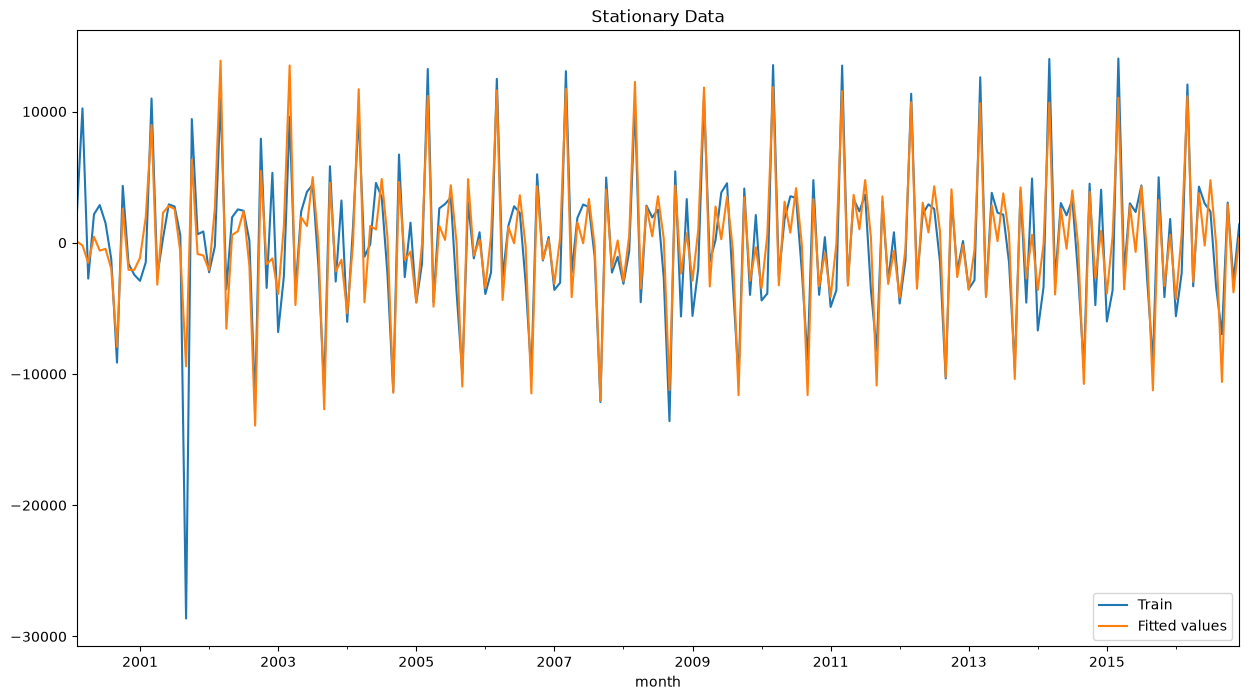

In [23]:
fig,ax = plt.subplots(figsize=(15,8))
stationary_train_df.plot(kind='line',ax=ax)
fitted_values.plot(kind='line',ax=ax)
plt.title('Stationary Data')
plt.legend(['Train','Fitted values'])
plt.show()

In [24]:
start_date = datetime.strptime('2017-01-01','%Y-%m-%d')
end_date = datetime.strptime('2019-12-01','%Y-%m-%d')
prediction_values = model_arma.predict(start=start_date,end=end_date) # stationary in nature

In [25]:
train_df.iloc[-1]

passengers    67983
Name: 2016-12-01 00:00:00, dtype: int64

In [26]:
# stationary to non-stationary
initial_value = train_df.iloc[-1]['passengers']
forecasted_values = prediction_values.cumsum() + initial_value

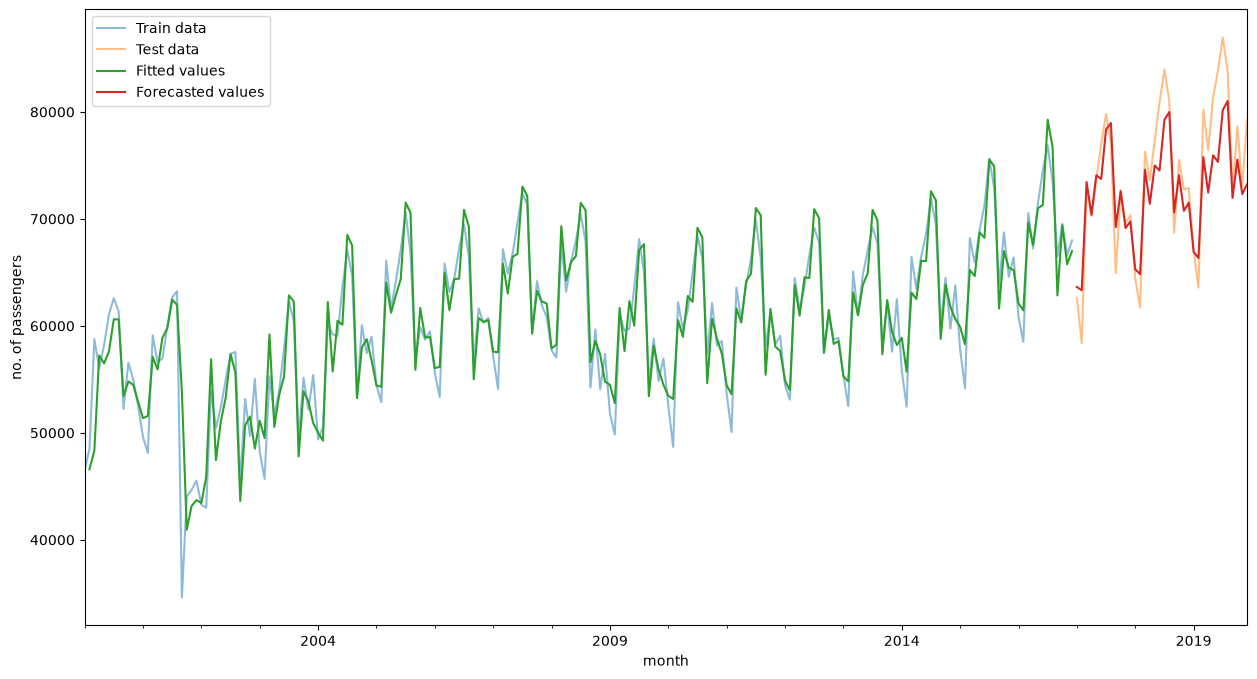

In [27]:
# fitted_values are differences (stationary scale) -- convert back to passenger levels:
# level(t) = actual(t-1) + predicted_diff(t)
fitted_levels = train_df['passengers'].shift(1) + fitted_values

# visualize
fig,ax = plt.subplots(figsize=(15,8))
train_df['passengers'].plot(kind='line',ax=ax, label='Train data',alpha=0.5)
test_df['passengers'].plot(kind='line',ax=ax, label='Test data',alpha=0.5)

fitted_levels.plot(kind='line',ax=ax, label='Fitted values')
forecasted_values.plot(kind='line',ax=ax, label='Forecasted values')
plt.xlabel('month')
plt.ylabel('no. of passengers')
plt.legend()
plt.show()

### ARIMA(p,d,q)
- (6,0,6)

In [28]:
model_arima = ARIMA(stationary_train_df,order=(6,0,6)).fit()

In [29]:
start_date = datetime.strptime('2017-01-01','%Y-%m-%d')
end_date = datetime.strptime('2019-12-01','%Y-%m-%d')
predicted_value_arima = model_arima.predict(start=start_date,end=end_date) # stationary in nature

In [30]:
train_df.iloc[-1]

passengers    67983
Name: 2016-12-01 00:00:00, dtype: int64

In [31]:
forecasted_values_arima = train_df.iloc[-1]['passengers'] + np.cumsum(predicted_value_arima)


In [32]:
len(forecasted_values_arima)

36

In [33]:
# confidence interval
# forecast() no longer returns (forecast, stderr, conf_int) -- use get_forecast().conf_int()
forecast_result = model_arima.get_forecast(steps=len(forecasted_values_arima))
confidence_interval = forecast_result.conf_int(alpha=0.05)  # 95% CI (on the differenced scale)
confidence_interval

,lower passengers,upper passengers
2017-01-01,-10211.968239,1508.115109
2017-02-01,-6213.261001,5606.318304
2017-03-01,4195.034368,16035.481153
2017-04-01,-9013.039639,2906.898410
2017-05-01,-2293.865237,9667.142116
2017-06-01,-6417.271866,5738.541757
2017-07-01,-1468.565231,10726.088018
2017-08-01,-5548.172960,6734.810973
2017-09-01,-15875.442755,-3575.897703
2017-10-01,-2848.476166,9520.472762


In [34]:
# confidence_interval above is on the DIFFERENCED scale (one step's change), so it can't be
# added to the cumulative level forecast. Fit the same model on the levels with d=1
# (ARIMA differences internally) -- its intervals are on the passenger scale and widen over time.
model_arima_levels = ARIMA(train_df['passengers'], order=(6,1,6), trend='t').fit()
level_ci = model_arima_levels.get_forecast(steps=len(forecasted_values_arima)).conf_int(alpha=0.05)
lower_lmt = level_ci.iloc[:, 0]
upper_lmt = level_ci.iloc[:, 1]

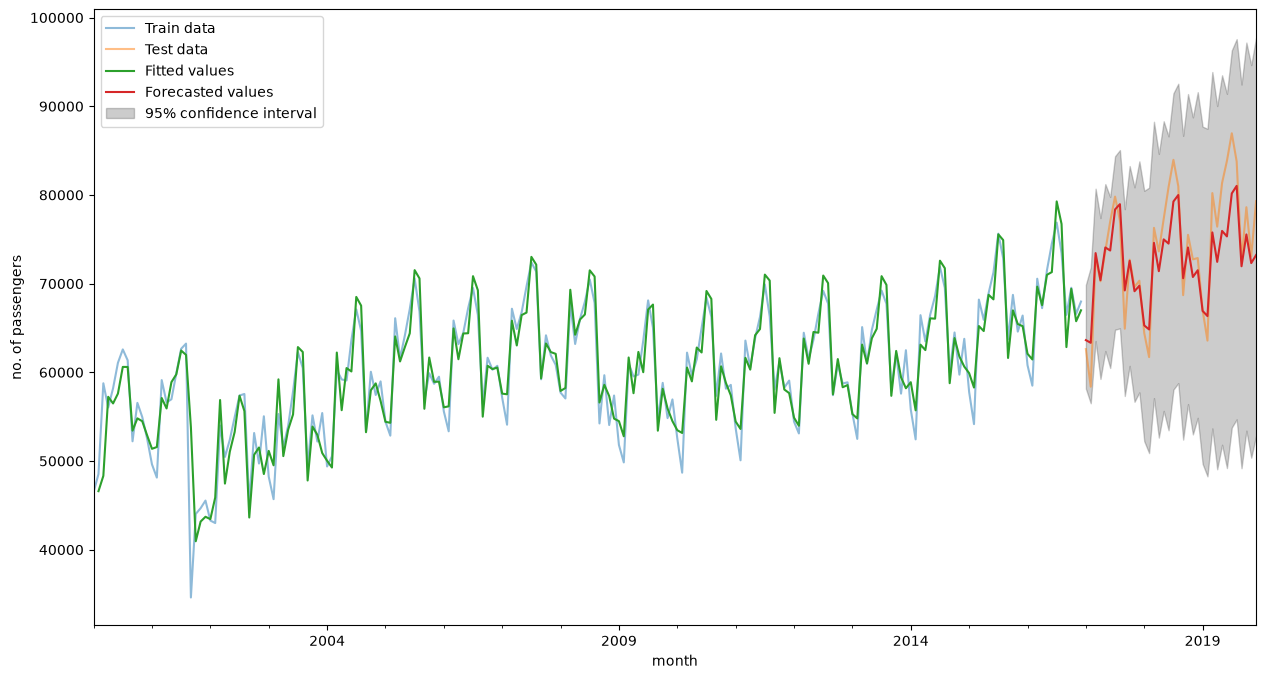

In [35]:
# fitted_values are differences (stationary scale) -- convert back to passenger levels:
# level(t) = actual(t-1) + predicted_diff(t)
fitted_levels = train_df['passengers'].shift(1) + fitted_values

# visualize
fig,ax = plt.subplots(figsize=(15,8))
train_df['passengers'].plot(kind='line',ax=ax, label='Train data',alpha=0.5)
test_df['passengers'].plot(kind='line',ax=ax, label='Test data',alpha=0.5)

fitted_levels.plot(kind='line',ax=ax, label='Fitted values')
forecasted_values_arima.plot(kind='line',ax=ax, label='Forecasted values')
ax.fill_between(lower_lmt.index, lower_lmt, upper_lmt, color='k', alpha=0.2, label='95% confidence interval')
plt.xlabel('month')
plt.ylabel('no. of passengers')
plt.legend()  # use the label= set on each plot call, so names can't get out of order
plt.show()